In [33]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from hcipy import * 
sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))
from slicing_class import adcFitter2

In [34]:
def colorbar(mappable):
    from mpl_toolkits.axes_grid1 import make_axes_locatable
    import matplotlib.pyplot as plt
    last_axes = plt.gca()
    ax = mappable.axes
    fig = ax.figure
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.1)
    cbar = fig.colorbar(mappable, cax=cax)
    plt.sca(last_axes)
    return cbar

import matplotlib.pylab as pylab
params = {'legend.fontsize': 'x-large',
          'figure.figsize': (12, 5),
         'axes.labelsize': 'large',
         'axes.titlesize':'large',
         'xtick.labelsize':'medium',
         'ytick.labelsize':'medium',
         'font.family':'serif'}
pylab.rcParams.update(params)

In [3]:
wavelength = 764E-9
bw = 126E-9
wavelength_normalized = wavelength / 656E-9
bw_normalized = bw / wavelength
grating_angle = 28
grating_freq = 47

ADC = adcFitter2(wavelength=wavelength,bandwidth=bw,grating_angle=grating_angle,grating_freq=grating_freq,snr_threshold=2.3,speckle_window=70)

In [35]:
cube = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/2026A/fieldcube_pt1_2dof.fits')

KeyboardInterrupt: 

In [5]:
cube_truncated = cube[0::5]
len(cube_truncated)

198

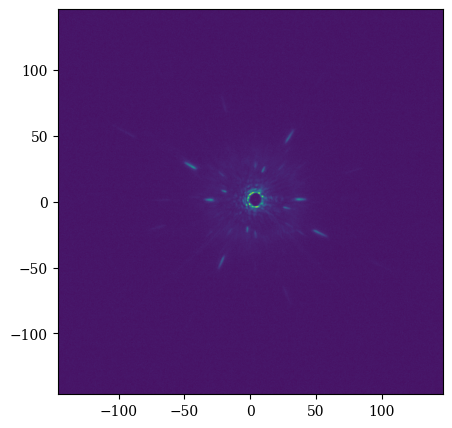

In [6]:
imshow_field(cube_truncated[0])

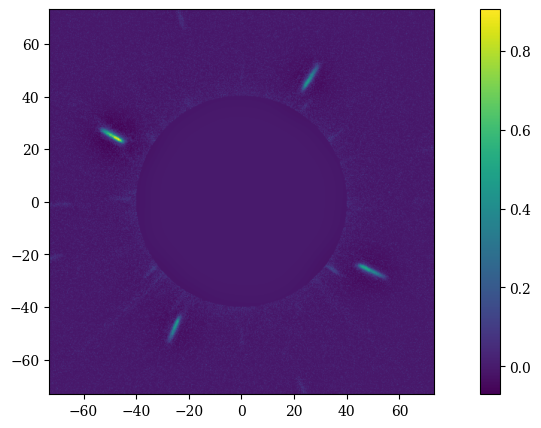

/Users/Katie/Documents/MagAO-X/simulations/adc_sims/slicing_class.py:26: RuntimeWarning: overflow encountered in exp
  return np.exp(-(x-mu)**2 / (2 * sigma2) )
/Users/Katie/Documents/MagAO-X/simulations/adc_sims/slicing_class.py:52: OptimizeWarning: Covariance of the parameters could not be estimated
  popt = curve_fit(self.gauss,x,isolated,p0=[np.argmax(data),2])
/Users/Katie/Documents/MagAO-X/simulations/adc_sims/.venv/lib/python3.13/site-packages/scipy/optimize/_minpack_py.py:497: RuntimeWarning: overflow encountered in matmul
  cov_x = invR @ invR.T


-3.909175850881622


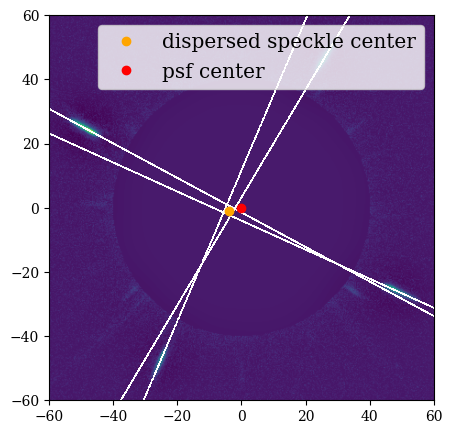

In [7]:
field = cube_truncated[0]
field = field - float(np.median(field))
#field = Field([x if x>0 else 0 for x in img],field.grid)
img = ADC.crop_image(field,mask_diam=80,extent=512) #COI method
hp = ADC.hpf(img,20)
hp = hp - ADC.hpf(hp,0.4)
imshow_field(hp)
plt.colorbar()
plt.show()

try:
    dx,dy = ADC.speckles_dxdy(hp,plotted=True)
except:
    dx = np.nan
    dy = np.nan

print(dx)

In [8]:
rel_x = []
rel_y = []

for i, field in enumerate(cube_truncated):
    if np.sum(field) > 0:
            #field = field - float(np.median(field))
            img = ADC.crop_image(field,mask_diam=80,extent=512) #COI method
            hp = ADC.hpf(img,20)
            hp = hp - ADC.hpf(hp,0.8)
            # imshow_field(hp)
            # plt.show()

            try:
                dx,dy = ADC.speckles_dxdy(hp,plotted=False)
            except:
                dx = np.nan
                dy = np.nan
            #plt.show()
        
            rel_x.append(dx)
            rel_y.append(dy)

KeyboardInterrupt: 

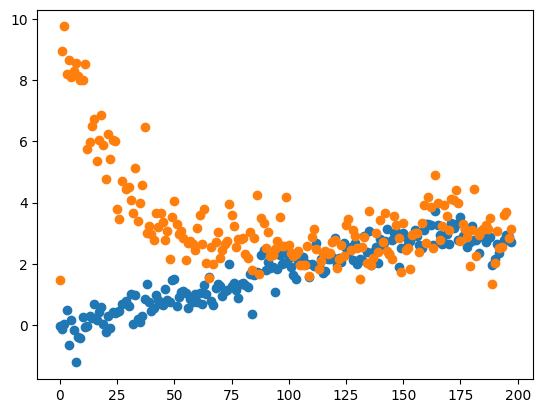

In [ ]:
plt.plot(rel_x,'o')
plt.plot(rel_y,'o')

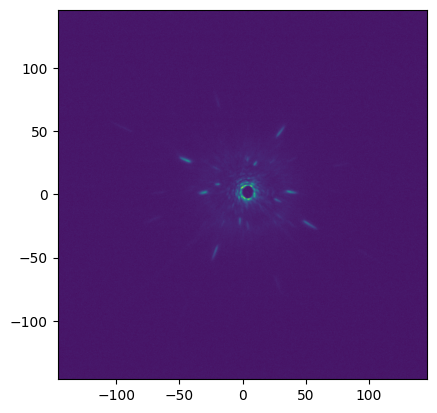

In [ ]:
img_before =  cube_truncated[2]
imshow_field(img_before)

In [36]:
img = read_fits('/Users/Katie/Documents/MagAO-X/Data/ADC/2026A/2026-03-31_072854_alfCir_adc_orientation_control/camsci1/camsci1_20260331073353346434094.fits')
dim = np.sqrt(img.size)
extent = dim * 6/21
pgrid = make_pupil_grid(dim,extent)
img = Field(img.ravel(),pgrid)

orientation_cube = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/2026A/fieldcube_orientation.fits')

In [37]:
wavelength = 764E-9
bw = 126E-9
wavelength_normalized = wavelength / 656E-9
bw_normalized = bw / wavelength
grating_angle = 0
grating_freq = 15

ADC = adcFitter2(wavelength=wavelength,bandwidth=bw,grating_angle=grating_angle,grating_freq=grating_freq,snr_threshold=2.3,speckle_window=70)

/Users/Katie/Documents/MagAO-X/simulations/adc_sims/slicing_class.py:26: RuntimeWarning: overflow encountered in exp
  return np.exp(-(x-mu)**2 / (2 * sigma2) )
/Users/Katie/Documents/MagAO-X/simulations/adc_sims/.venv/lib/python3.13/site-packages/scipy/optimize/_minpack_py.py:497: RuntimeWarning: overflow encountered in matmul
  cov_x = invR @ invR.T
/Users/Katie/Documents/MagAO-X/simulations/adc_sims/slicing_class.py:52: OptimizeWarning: Covariance of the parameters could not be estimated
  popt = curve_fit(self.gauss,x,isolated,p0=[np.argmax(data),2])


(np.float64(-2.5177634431837874), np.float64(-0.401693586114331))

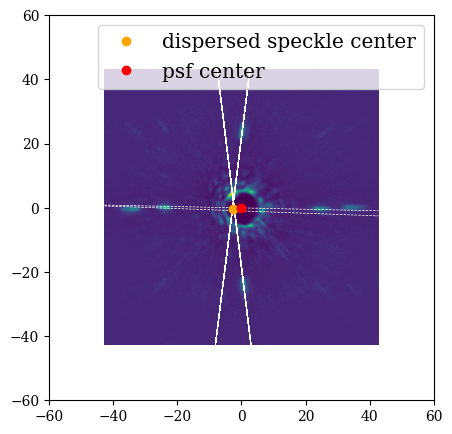

In [38]:
ADC.speckles_dxdy(img_before,plotted=True)

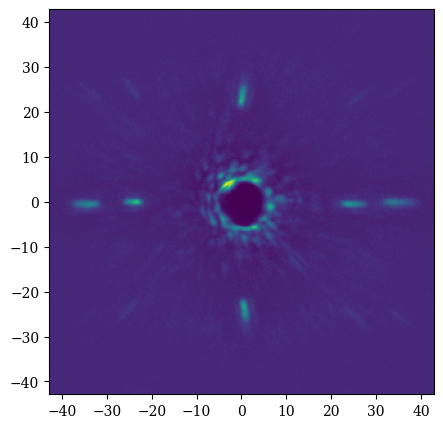

In [39]:
imshow_field(img_before)

In [59]:
img_before = orientation_cube[4]
#img_before = ADC.crop_image(img_before,extent=300,mask_diam=0)
img_before = img_before - float(np.median(img_before))
#img_before = img_before([x if x>0 else 0 for x in img],img_before.grid)
hp = ADC.crop_image(img_before,mask_diam=0,extent=210) #COI method
hp = ADC.hpf(hp,20)
img_before = hp - ADC.hpf(hp,0.4)

img_after = img
img_after = img_after - float(np.median(img_after))
#img_after = img_after([x if x>0 else 0 for x in img],img_after.grid)
hp = ADC.crop_image(img_after,mask_diam=0,extent=210) #COI method
hp = ADC.hpf(hp,20)
img_after = hp - ADC.hpf(hp,0.4)

# plt.figure(figsize=(10,4))
# plt.subplot(1,2,1)
# dx,dy = ADC.speckles_dxdy(img_before,plotted=True)
# plt.title('Before')
# plt.legend()

# plt.subplot(1,2,2)
# dx,dy = ADC.speckles_dxdy(img_after,plotted=True)
# plt.title('After')
# plt.legend()
# plt.show()

[]

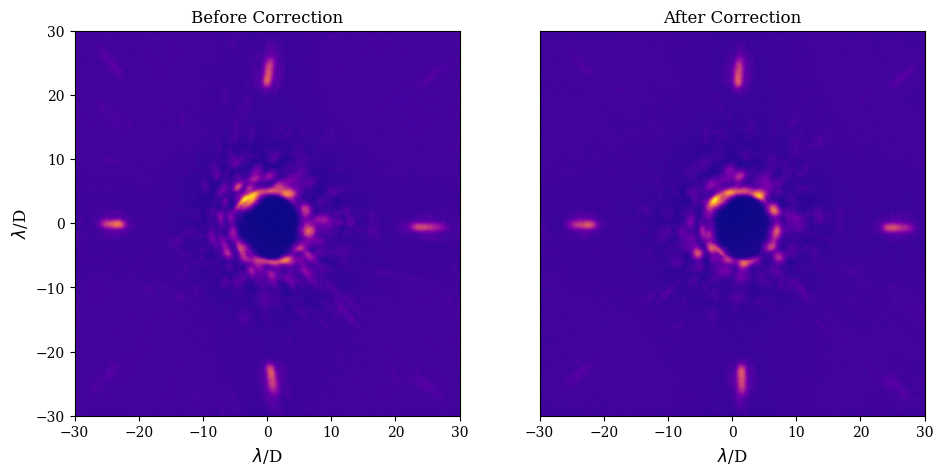

In [60]:
fig, ax = plt.subplots(1,2,figsize=(11,5))
bf = imshow_field(img_before,ax=ax[0],cmap='plasma')
af = imshow_field(img_after,ax=ax[1],cmap='plasma')

#figure params
ax[0].set_box_aspect(1)
ax[1].set_box_aspect(1)

# ax[0].set_ylim((-40,40))
# ax[0].set_xlim((-40,40))

# ax[1].set_ylim((-40,40))
# ax[1].set_xlim((-40,40))

ax[0].set_title('Before Correction')
ax[1].set_title('After Correction')

ax[0].set_xlabel(r'$\lambda$/D')
ax[1].set_xlabel(r'$\lambda$/D')
ax[0].set_ylabel(r'$\lambda$/D')

ax[1].set_yticks([])

In [61]:
fig.savefig('/Users/Katie/Documents/MagAO-X/figures/ADC/SPIE_26/alphcir_beforeafter_cropped')

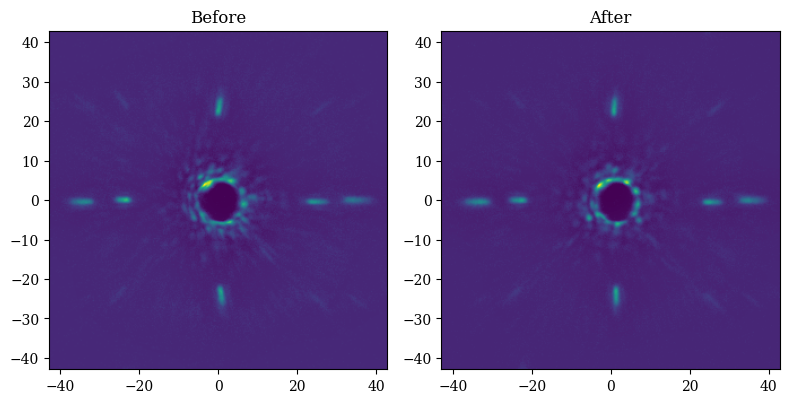

In [24]:
plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
imshow_field(img_before)
plt.title('Before')

plt.subplot(1,2,2)
imshow_field(img_after)
plt.title('After')
plt.tight_layout()
plt.show()